Principal Component Analysis for Backgorund and Foreground separation

In [64]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Importing the data and processing each frame and flattening them and appending them to prepare a matrix X  which has n x m dimensions where n represents the number of frames and m represents the pixels 

In [65]:
DATASET_PATH = "../data/boats/input"

image_files = sorted([
    f for f in os.listdir(DATASET_PATH)
    if f.endswith(".jpg")
])

In [87]:
frames = []

for file in image_files[1900:2100]:

    img_path = os.path.join(DATASET_PATH, file)

    frame = cv2.imread(img_path)

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    gray = cv2.resize(gray, (160,120))

    x = gray.flatten().astype(np.float64)/255

    frames.append(x)

In [88]:
X = np.vstack(frames)

print(X.shape)
print(X.dtype)

(200, 19200)
float64


PCA needs mean centering :
Reason : need to learn

In [89]:
mean_frame = np.mean(X, axis=1, keepdims=True)

X_centered = X - mean_frame

We are finding the singular values of the matrix x and left singular vectors (column vectors of U) and right singular vectors (column vectors of V) using singular value decomposition technique which says x^Tx -> eigen vectors of this gives right singular vectors and xx^T gives the left singular vectors 

In [90]:
U, S, VT = np.linalg.svd(X_centered, full_matrices=False)

print(S.shape)

(200,)


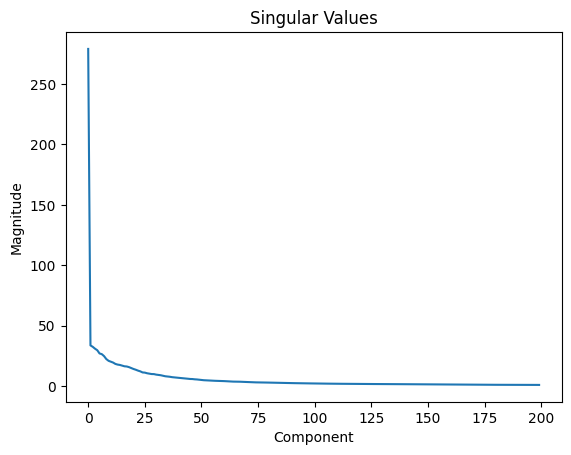

In [91]:
plt.plot(S)
plt.title("Singular Values")
plt.xlabel("Component")
plt.ylabel("Magnitude")
plt.show()

To find the ideal K value we plot the graph for k vs frobenius norm of x - x' and we choose the knee point in the graph which will be the ideal value of K

In [92]:
errors_squared = []
errors = []
k_values = range(1,101)

for k in k_values:
    # ||X - X_k||_F^2
    error_squared = np.sum(S[k+1:] ** 2)
    # ||X - X_k||_F
    error = np.sqrt(error_squared)

    errors_squared.append(error_squared)
    errors.append(error)
    

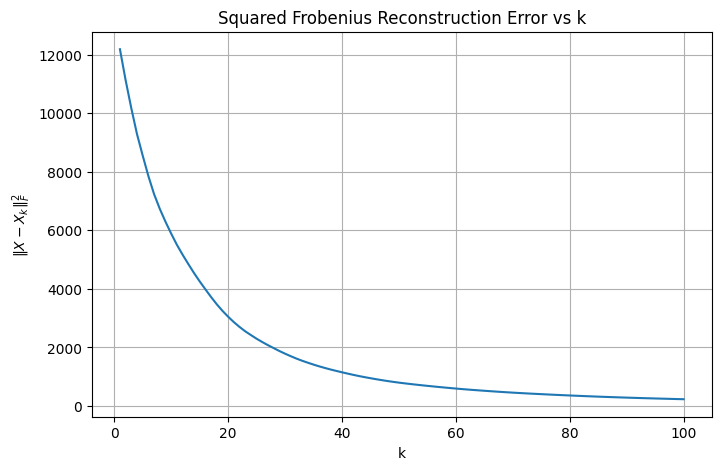

In [93]:
plt.figure(figsize=(8, 5))
plt.plot(k_values, errors_squared)

plt.xlabel("k")
plt.ylabel(r"$\|X - X_k\|_F^2$")
plt.title("Squared Frobenius Reconstruction Error vs k")
plt.grid(True)

plt.show()

In [94]:
k=30

In [95]:
Uk = U[:, :k]
Sk = S[:k]
VTk = VT[:k, :]

X_reconstructed = (Uk * Sk) @ VTk

/var/folders/jb/4w53x6j16lg901xfnf6463dr0000gn/T/ipykernel_1268/3892235525.py:5: RuntimeWarning: divide by zero encountered in matmul
  X_reconstructed = (Uk * Sk) @ VTk
/var/folders/jb/4w53x6j16lg901xfnf6463dr0000gn/T/ipykernel_1268/3892235525.py:5: RuntimeWarning: overflow encountered in matmul
  X_reconstructed = (Uk * Sk) @ VTk
/var/folders/jb/4w53x6j16lg901xfnf6463dr0000gn/T/ipykernel_1268/3892235525.py:5: RuntimeWarning: invalid value encountered in matmul
  X_reconstructed = (Uk * Sk) @ VTk


In [96]:
X_reconstructed += mean_frame

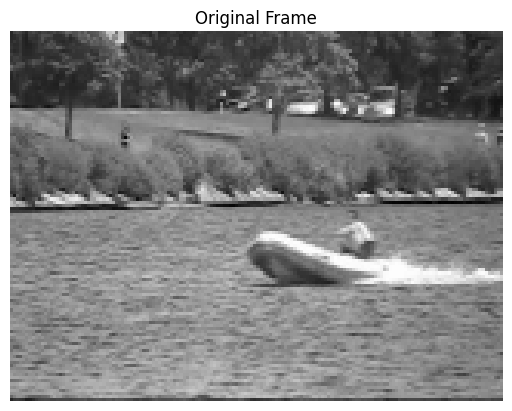

In [97]:
original = X[78,:].reshape(120,160)

plt.imshow(original, cmap='gray')
plt.title("Original Frame")
plt.axis("off")
plt.show()

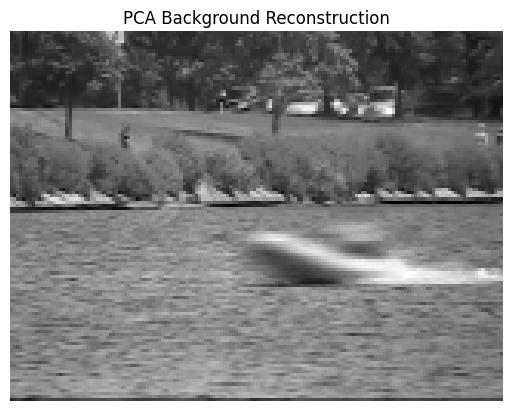

In [98]:
background = X_reconstructed[78,:].reshape(120,160)

plt.imshow(background, cmap='gray')
plt.title("PCA Background Reconstruction")
plt.axis("off")
plt.show()

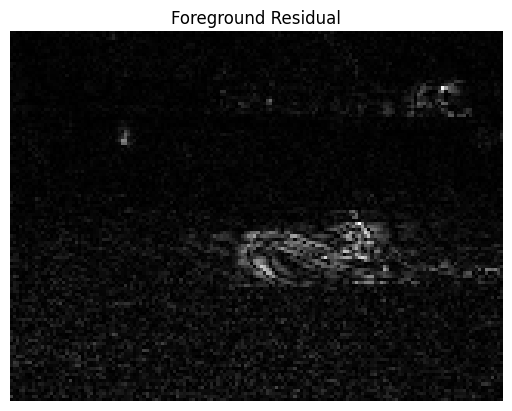

2.0589589166952749e-07
0.3084737252075087
0.014237690346493808


In [99]:
foreground = np.abs(
    X[78,:] - X_reconstructed[78,:]
)

foreground = foreground.reshape(120,160)

plt.imshow(foreground, cmap='gray')
plt.title("Foreground Residual")
plt.axis("off")
plt.show()

print(np.min(foreground))
print(np.max(foreground))
print(np.mean(foreground))

In [100]:
Ground_path = "../data/boats/groundtruth"

In [101]:
sorted(os.listdir(Ground_path))[:5]

['gt000001.png',
 'gt000002.png',
 'gt000003.png',
 'gt000004.png',
 'gt000005.png']

Storing the ground truth mask for calculating precision accuracy and F1 score 

In [102]:
gt_files = sorted([
    f for f in os.listdir(Ground_path)
    if f.endswith(".png")
])

In [117]:
gt_masks = []
valid_masks = []

for file in gt_files[1900:2100]:

    gt_path = os.path.join(Ground_path, file)

    gt = cv2.imread(
        gt_path,
        cv2.IMREAD_GRAYSCALE
    )

    gt = cv2.resize(
        gt,
        (160, 120),
        interpolation=cv2.INTER_NEAREST
    )

    # 255 = foreground
    gt_binary = (gt == 255).astype(np.uint8)

    # Valid pixels: background, shadow, foreground
    # Ignore 85 and 170
    valid = (
        (gt == 0) |
        (gt == 50) |
        (gt == 255)
    )

    gt_masks.append(gt_binary)
    valid_masks.append(valid)

gt_masks = np.stack(gt_masks)
valid_masks = np.stack(valid_masks)

print(gt_masks.shape)
print(np.unique(gt_masks))

(200, 120, 160)
[0 1]


Finding the appropriate threshold values so that the method is performing well. To find we iterarte through various values of threshold and k values to find the appropriate values of each.

In [118]:
k_values = range(1,21)

In [119]:
results = []

In [120]:
results = []
thresholds = [0.01, 0.02, 0.03, 0.05, 0.07, 0.10, 0.15]

for threshold in thresholds:

    for k in k_values:

        # reconstruction
        Uk = U[:, :k]
        Sk = S[:k]
        VTk = VT[:k, :]

        X_reconstructed = np.dot(
            Uk * Sk,
            VTk
        )

        X_reconstructed += mean_frame

        pred_masks = []

        # generate masks
        for i in range(200):

            foreground = np.abs(
                X[i,:] - X_reconstructed[i,:]
            )

            foreground = foreground.reshape(120,160)

            mask = (
                foreground > threshold
            ).astype(np.uint8)

            pred_masks.append(mask)

        # flatten
        y_pred = np.concatenate([
            m.flatten() for m in pred_masks
        ])

        y_true = np.concatenate([
            g.flatten() for g in gt_masks
        ])

        # confusion matrix
        TP = np.sum((y_pred == 1) & (y_true == 1))

        TN = np.sum((y_pred == 0) & (y_true == 0))

        FP = np.sum((y_pred == 1) & (y_true == 0))

        FN = np.sum((y_pred == 0) & (y_true == 1))

        # metrics
        precision = TP / (TP + FP + 1e-8)

        recall = TP / (TP + FN + 1e-8)

        f1 = (
            2 * precision * recall
            / (precision + recall + 1e-8)
        )

        acc = (TP+TN)/(TP+TN+FP+FN+1e-8)

        # STORE RESULTS
        results.append({
            "threshold": threshold,
            "k": k,
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "accuracy":acc
        })

        

In [125]:
df = pd.DataFrame(results)
display(df[df['k'] == 2])

,threshold,k,precision,recall,f1,accuracy
1,0.01,2,0.017685,0.979534,0.034742,0.364215
21,0.02,2,0.024903,0.958309,0.048544,0.561207
41,0.03,2,0.032468,0.936706,0.062761,0.673216
61,0.05,2,0.051963,0.894814,0.098222,0.808079
81,0.07,2,0.083041,0.853547,0.151357,0.888198
101,0.10,2,0.158180,0.786552,0.263391,0.948612
121,0.15,2,0.311333,0.661502,0.423397,0.978954


In [130]:
best = df[df["k"] > 5].loc[
    df[df["k"] > 5]["f1"].idxmax()
]

print(best)

threshold    0.150000
k            6.000000
precision    0.336181
recall       0.474651
f1           0.393592
accuracy     0.982916
Name: 125, dtype: float64


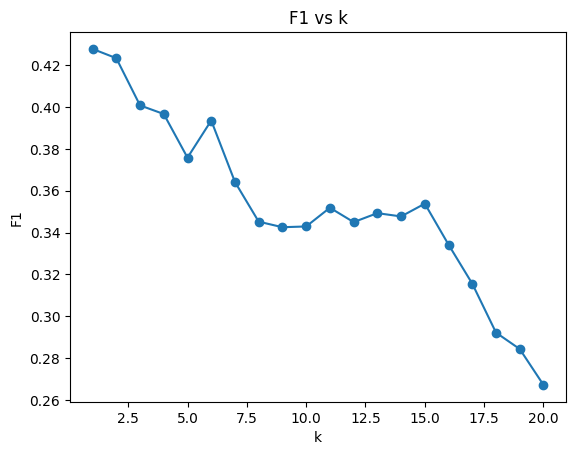

In [123]:
subset = df[df["threshold"] == 0.15]

plt.plot(
    subset["k"],
    subset["f1"],
    marker='o'
)

plt.xlabel("k")
plt.ylabel("F1")
plt.title("F1 vs k")
plt.grid(False)
plt.show()

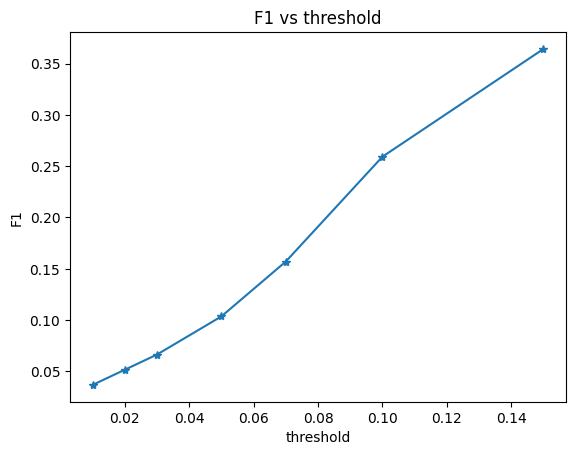

In [124]:
subset = df[df["k"] == 7]

plt.plot(
    subset["threshold"],
    subset["f1"],
    marker='*'
)

plt.xlabel("threshold")
plt.ylabel("F1")
plt.title("F1 vs threshold")
plt.grid(False)
plt.show()